# Pair 3 — LightGCL (authors’ method adapted to Amazon)

I evaluate LightGCL for Amazon Musical Instruments recommendations using 10,000 users and 17,233 training products. This notebook follows the authors’ graph propagation, SVD global view, all-user/all-item contrastive loss, BPR and regularisation. I adapt the data loading, low-rank SVD calculation and evaluation to my dataset and environment.

Source: [LightGCL official implementation](https://github.com/HKUDS/LightGCL) (Cai et al., ICLR 2023). This is a close adaptation, not an unmodified reproduction.

## 1. Setup


In [1]:
from pathlib import Path
import json, random, time, copy
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.sparse.linalg import svds
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

BASE = Path.cwd()
if not (BASE / "datasets" / "processed" / "train.csv").exists():
    BASE = BASE / "Models" / "Pair_03"
DATA = BASE / "datasets" / "processed"
OUT = BASE / "results" / "LightGCL"
OUT.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PILOT = False

DIM = 64
LAYERS = 1      # Official Amazon example uses one layer
RANK = 5         # Official default SVD rank
TEMP = 0.1       # Official Amazon example
LAMBDA_CL = 0.01   # best results
LAMBDA_L2 = 0.0   # Official Amazon example
DROPOUT = 0.0     # Official default
LR = 0.001
BATCH_SIZE = 1024
EPOCHS = 3 if PILOT else 100
PATIENCE = 5
print("Device:", DEVICE, "| Data:", DATA)

Device: cuda | Data: c:\Users\royay\OneDrive\Desktop\COMP8410\Assignment 1\COMP8410_A1_49128299\Models\Pair_03\datasets\processed


## 2. Load interactions and construct the graph

Only training interactions form the user-item graph. Validation is used for model selection, and test data is held out until the end. I do not use the `history` column to create extra edges.

In [2]:
train = pd.read_csv(DATA / "train.csv")
valid = pd.read_csv(DATA / "valid.csv")
test = pd.read_csv(DATA / "test.csv")

for name, df in [("train", train), ("valid", valid), ("test", test)]:
    assert {"user_idx", "item_idx"}.issubset(df.columns), f"Missing columns in {name}"
    assert not df[["user_idx", "item_idx"]].isna().any().any()
    df["user_idx"] = df["user_idx"].astype(int)
    df["item_idx"] = df["item_idx"].astype(int)

N_USERS = int(train.user_idx.max()) + 1
N_ITEMS = int(train.item_idx.max()) + 1
assert np.array_equal(np.sort(train.user_idx.unique()), np.arange(N_USERS))
assert np.array_equal(np.sort(train.item_idx.unique()), np.arange(N_ITEMS))
for df in (valid, test):
    assert df.user_idx.between(0, N_USERS - 1).all()
    assert df.item_idx.between(0, N_ITEMS - 1).all()

rows = train.user_idx.to_numpy()
cols = train.item_idx.to_numpy()
R = sp.coo_matrix((np.ones(len(train), dtype=np.float32), (rows, cols)),
                  shape=(N_USERS, N_ITEMS)).tocsr()
R.data[:] = 1.0

def normalise_bipartite(matrix):
    row_deg = np.asarray(matrix.sum(axis=1)).ravel()
    col_deg = np.asarray(matrix.sum(axis=0)).ravel()
    left = 1.0 / np.sqrt(np.maximum(row_deg, 1))
    right = 1.0 / np.sqrt(np.maximum(col_deg, 1))
    return sp.diags(left) @ matrix @ sp.diags(right)

A = normalise_bipartite(R).tocoo()
idx = torch.from_numpy(np.vstack([A.row, A.col]).astype(np.int64))
vals = torch.from_numpy(A.data.astype(np.float32))
ADJ = torch.sparse_coo_tensor(idx, vals, A.shape).coalesce().to(DEVICE)
ADJ_T = ADJ.transpose(0, 1).coalesce()

seen = [set(R.getrow(u).indices.tolist()) for u in range(N_USERS)]
print("Users:", N_USERS, "| Items:", N_ITEMS, "| Train edges:", R.nnz)
print("Validation:", len(valid), "| Test:", len(test))

Users: 10000 | Items: 17233 | Train edges: 59681
Validation: 7425 | Test: 7148


## 3. SVD view

The authors use a low-rank SVD of the normalised interaction graph. I compute the top singular vectors with SciPy (`svds`) on CPU instead of `torch.svd_lowrank` on GPU. The resulting factors are used in the same low-rank propagation equations.

In [3]:
svd_start = time.perf_counter()
U, S, VT = svds(A.tocsr(), k=RANK, return_singular_vectors=True,
                random_state=SEED)
order = np.argsort(S)[::-1]
U, S, VT = U[:, order].copy(), S[order].copy(), VT[order].copy()
US = torch.tensor(U * S, dtype=torch.float32, device=DEVICE)
VS = torch.tensor(VT.T * S, dtype=torch.float32, device=DEVICE)
UT = torch.tensor(U.T.copy(), dtype=torch.float32, device=DEVICE)
VT_T = torch.tensor(VT.copy(), dtype=torch.float32, device=DEVICE)
print(f"SVD rank {RANK} ready in {time.perf_counter() - svd_start:.2f}s")

SVD rank 5 ready in 0.11s


## 4. Model and objective

The local view propagates embeddings across graph edges; the global view propagates through low-rank SVD factors. I sum representations across layers and train using BPR, full user/item contrastive negatives and L2 regularisation. The contrastive denominator is implemented with `logsumexp` for numerical stability.

In [4]:
class LightGCL(nn.Module):
    def __init__(self, n_users, n_items, dim):
        super().__init__()
        self.user = nn.Parameter(torch.empty(n_users, dim))
        self.item = nn.Parameter(torch.empty(n_items, dim))
        nn.init.xavier_uniform_(self.user)
        nn.init.xavier_uniform_(self.item)

    def propagate(self, training=False):
        local_u, local_i = self.user, self.item
        global_u, global_i = self.user, self.item
        sum_local_u, sum_local_i = local_u, local_i
        sum_global_u, sum_global_i = global_u, global_i
        for _ in range(LAYERS):
            adj = ADJ
            adj_t = ADJ_T
            if training and DROPOUT > 0:
                dropped = F.dropout(ADJ.values(), p=DROPOUT, training=True)
                adj = torch.sparse_coo_tensor(ADJ.indices(), dropped, ADJ.shape).coalesce()
                adj_t = adj.transpose(0, 1).coalesce()
            next_local_u = torch.sparse.mm(adj, local_i)
            next_local_i = torch.sparse.mm(adj_t, local_u)
            next_global_u = US @ (VT_T @ local_i)
            next_global_i = VS @ (UT @ local_u)
            local_u, local_i = next_local_u, next_local_i
            global_u, global_i = next_global_u, next_global_i
            sum_local_u = sum_local_u + local_u
            sum_local_i = sum_local_i + local_i
            sum_global_u = sum_global_u + global_u
            sum_global_i = sum_global_i + global_i
        return sum_local_u, sum_local_i, sum_global_u, sum_global_i

    def loss(self, users, positive, negative):
        eu, ei, gu, gi = self.propagate(training=True)
        pos_scores = (eu[users] * ei[positive]).sum(dim=1)
        neg_scores = (eu[users] * ei[negative]).sum(dim=1)
        bpr = F.softplus(neg_scores - pos_scores).mean()

        # In the official code, the item anchors contain positive and negative items.
        item_ids = torch.cat([positive, negative])
        user_logits = (gu[users] @ eu.T) / TEMP
        item_logits = (gi[item_ids] @ ei.T) / TEMP
        user_pos = ((gu[users] * eu[users]).sum(dim=1) / TEMP).clamp(-5, 5)
        item_pos = ((gi[item_ids] * ei[item_ids]).sum(dim=1) / TEMP).clamp(-5, 5)
        contrastive = (torch.logsumexp(user_logits, dim=1).mean() - user_pos.mean()
                       + torch.logsumexp(item_logits, dim=1).mean() - item_pos.mean())
        reg = LAMBDA_L2 * (self.user.square().sum() + self.item.square().sum())
        return bpr + LAMBDA_CL * contrastive + reg, bpr, contrastive

model = LightGCL(N_USERS, N_ITEMS, DIM).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
print("Parameters:", sum(p.numel() for p in model.parameters()))

Parameters: 1742912


## 5. Full-catalog evaluation

I rank all training-catalogue items and mask products the user already interacted with in training. One positive target is available per eligible user in this processed dataset.

In [5]:
@torch.no_grad()
def evaluate(df, return_details=False):
    model.eval()
    eu, ei, _, _ = model.propagate()
    targets = df.groupby("user_idx")["item_idx"].apply(set).to_dict()
    results = []
    recommended = set()
    for start in range(0, len(targets), 256):
        ids = list(targets)[start:start + 256]
        uid = torch.tensor(ids, dtype=torch.long, device=DEVICE)
        scores = eu[uid] @ ei.T
        for j, u in enumerate(ids):
            scores[j, list(seen[u])] = -float("inf")
        top = scores.topk(20, dim=1).indices.cpu().numpy()
        for u, ranked in zip(ids, top):
            recommended.update(map(int, ranked))
            truth = targets[u]
            rec = {"user_idx": int(u)}
            for k in (10, 20):
                hits = np.array([int(int(x) in truth) for x in ranked[:k]])
                rec[f"recall_at_{k}"] = float(hits.sum() / len(truth))
                dcg = float((hits / np.log2(np.arange(2, k + 2))).sum())
                ideal = float((1 / np.log2(np.arange(2, min(k, len(truth)) + 2))).sum())
                rec[f"ndcg_at_{k}"] = dcg / ideal if ideal else 0.0
            if return_details:
                rec["target_items"] = " ".join(map(str, sorted(truth)))
                rec["top20_items"] = " ".join(map(str, ranked))
            results.append(rec)
    detail = pd.DataFrame(results)
    cols = [f"{m}_at_{k}" for m in ("recall", "ndcg") for k in (10, 20)]
    summary = {col: float(detail[col].mean()) for col in cols}
    summary["coverage_at_20"] = len(recommended) / N_ITEMS
    summary["evaluated_users"] = len(detail)
    return summary, detail

# Each epoch samples a different negative item not already seen by the user.
def make_negatives(users, rng):
    negatives = rng.integers(0, N_ITEMS, size=len(users))
    for j, u in enumerate(users):
        while int(negatives[j]) in seen[int(u)]:
            negatives[j] = rng.integers(0, N_ITEMS)
    return negatives

## 6. Training

I select the best checkpoint using validation NDCG@20 and report test results only after training. The pilot runs three epochs with four batches per epoch; full training uses all training edges each epoch.

In [6]:
rng = np.random.default_rng(SEED)
train_users = train.user_idx.to_numpy(dtype=np.int64)
train_items = train.item_idx.to_numpy(dtype=np.int64)
history = []
best_score, best_epoch, stale = -1.0, 0, 0
checkpoint = OUT / ("lightgcl_pilot.pt" if PILOT else "lightgcl_best.pt")
start_time = time.perf_counter()

for epoch in range(1, EPOCHS + 1):
    indices = rng.permutation(len(train))
    negatives = make_negatives(train_users, rng)
    losses = []
    for j, begin in enumerate(range(0, len(indices), BATCH_SIZE)):
        if PILOT and j >= 4:
            break
        idx = indices[begin:begin + BATCH_SIZE]
        users = torch.tensor(train_users[idx], device=DEVICE)
        positives = torch.tensor(train_items[idx], device=DEVICE)
        negs = torch.tensor(negatives[idx], device=DEVICE)
        model.train()
        optimizer.zero_grad()
        total, bpr, contrastive = model.loss(users, positives, negs)
        total.backward()
        optimizer.step()
        losses.append(float(total.detach().cpu()))
    validation, _ = evaluate(valid)
    score = validation["ndcg_at_20"]
    history.append({"epoch": epoch, "loss": np.mean(losses), "val_ndcg_at_20": score})
    print(f"Epoch {epoch:02d}: loss={np.mean(losses):.4f}, val NDCG@20={score:.4f}")
    if score > best_score + 1e-7:
        best_score, best_epoch, stale = score, epoch, 0
        torch.save(model.state_dict(), checkpoint)
    else:
        stale += 1
        if stale >= PATIENCE:
            print("Early stopping")
            break

train_seconds = time.perf_counter() - start_time
pd.DataFrame(history).to_csv(OUT / ("history_pilot.csv" if PILOT else "history.csv"), index=False)
print(f"Best epoch: {best_epoch} | Validation NDCG@20: {best_score:.4f} | Training: {train_seconds:.1f}s")

Epoch 01: loss=0.8702, val NDCG@20=0.0124
Epoch 02: loss=0.8115, val NDCG@20=0.0203
Epoch 03: loss=0.6933, val NDCG@20=0.0233
Epoch 04: loss=0.5693, val NDCG@20=0.0235
Epoch 05: loss=0.4791, val NDCG@20=0.0245
Epoch 06: loss=0.4226, val NDCG@20=0.0244
Epoch 07: loss=0.3874, val NDCG@20=0.0242
Epoch 08: loss=0.3642, val NDCG@20=0.0247
Epoch 09: loss=0.3486, val NDCG@20=0.0246
Epoch 10: loss=0.3380, val NDCG@20=0.0248
Epoch 11: loss=0.3302, val NDCG@20=0.0248
Epoch 12: loss=0.3239, val NDCG@20=0.0249
Epoch 13: loss=0.3185, val NDCG@20=0.0253
Epoch 14: loss=0.3148, val NDCG@20=0.0255
Epoch 15: loss=0.3115, val NDCG@20=0.0258
Epoch 16: loss=0.3083, val NDCG@20=0.0265
Epoch 17: loss=0.3057, val NDCG@20=0.0268
Epoch 18: loss=0.3038, val NDCG@20=0.0267
Epoch 19: loss=0.3022, val NDCG@20=0.0271
Epoch 20: loss=0.3005, val NDCG@20=0.0273
Epoch 21: loss=0.2992, val NDCG@20=0.0275
Epoch 22: loss=0.2983, val NDCG@20=0.0276
Epoch 23: loss=0.2967, val NDCG@20=0.0276
Epoch 24: loss=0.2954, val NDCG@20

## 7. Test results and figures

The test set is evaluated once using the checkpoint chosen on validation data. Results are saved separately from the earlier simplified notebook.

recall_at_10         0.036794
recall_at_20         0.058478
ndcg_at_10           0.019543
ndcg_at_20           0.025038
coverage_at_20       0.795277
evaluated_users          7148
best_epoch                 62
train_seconds      187.170571
test_seconds         1.306342
pilot                   False
layers                      1
svd_rank                    5


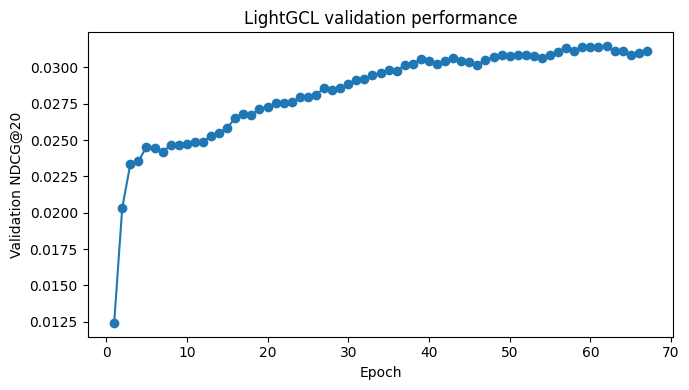

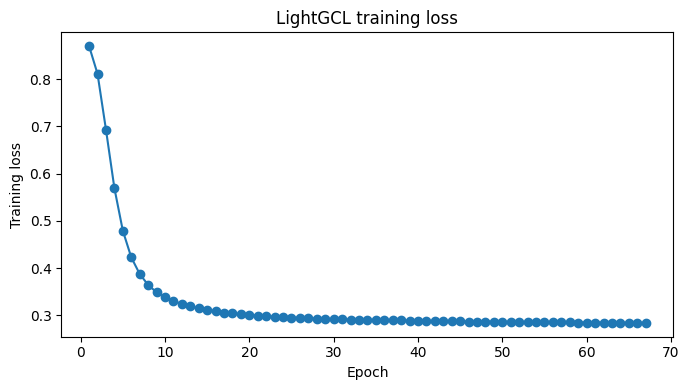

In [8]:
model.load_state_dict(torch.load(checkpoint, map_location=DEVICE, weights_only=True))
t0 = time.perf_counter()
test_metrics, details = evaluate(test, return_details=True)
test_seconds = time.perf_counter() - t0
metrics = {**test_metrics, "best_epoch": best_epoch, "train_seconds": train_seconds,
           "test_seconds": test_seconds, "pilot": PILOT, "layers": LAYERS, "svd_rank": RANK}
print(pd.Series(metrics).to_string())
suffix = "_pilot" if PILOT else ""
with open(OUT / f"metrics{suffix}.json", "w") as f:
    json.dump(metrics, f, indent=2)
details.to_csv(OUT / f"test_recommendations{suffix}.csv", index=False)

h = pd.DataFrame(history)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(h.epoch, h.val_ndcg_at_20, marker="o")
ax.set(xlabel="Epoch", ylabel="Validation NDCG@20", title="LightGCL validation performance")
plt.tight_layout()
plt.savefig(OUT / f"validation_curve{suffix}.png", dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(h.epoch, h.loss, marker="o")
ax.set(xlabel="Epoch", ylabel="Training loss", title="LightGCL training loss")
plt.tight_layout()
plt.savefig(OUT / f"training_loss{suffix}.png", dpi=160)
plt.show()

# Results and Discussion

I tested different contrastive-loss weights, SVD ranks, embedding dimensions and graph layers for LightGCL. The best configuration used a contrastive weight of 0.01, SVD rank 5 and one graph layer. With extended training, validation NDCG@20 reached 0.0315 at epoch 62.

The selected model achieved test Recall@20 of 0.0585, NDCG@20 of 0.0250 and item coverage of 79.53%. These results improved substantially over the initial configuration, although recommendation accuracy remains low.

The experiments showed that reducing the contrastive-loss weight had a larger impact than increasing SVD rank, embedding dimensions or graph depth. However, the sparse interaction history and large product catalogue remain challenges for recommendation quality.

**Reference:** Cai, X., Huang, C., Xia, L., & Ren, X. (2023). *LightGCL: Simple Yet Effective Graph Contrastive Learning for Recommendation*. ICLR. https://github.com/HKUDS/LightGCL